#### CA1 – Apartment Price Prediction Using Machine Learning
**Module:** Machine Learning  
**Programme:** Higher Diploma in Data Analytics for Business  
**Student ID:** 2026328  
**Assignment:** CA1  
**Project Topic:** Apartment Price Prediction in Mongolia  
**Data Source:** [Unegui.mn](https://www.unegui.mn/l-hdlh/l-hdlh-zarna/)  
**GitHub Repository:** https://github.com/2026328-Dashzeveg-Purevtogtokh/Machine-Learning-Sep26


---
**Introduction:** 
Apartment prices in Mongolia can vary depending on several factors, such as location, apartment size, number of rooms, and building year. Understanding these factors is important for buyers, sellers, and property investors.
The aim of this project is to develop Machine Learning models to predict apartment asking prices in Mongolia. The dataset was collected from [Unegui.mn](https://www.unegui.mn/l-hdlh/l-hdlh-zarna/), an online classified advertisements website. It contains information about apartment prices and property characteristics.
This project includes data cleaning, Exploratory Data Analysis (EDA), feature selection, model training, and evaluation. Linear Regression and Random Forest will be used to compare prediction performance.
The results may help us understand which apartment features are useful for predicting prices. However, the dataset contains advertised prices rather than confirmed selling prices.

**Project Aim:**
The main aim of this project is to develop and evaluate Machine Learning regression models to predict apartment asking prices in Mongolia using property information collected from Unegui.mn.

#### 1. Data Loading and Preparation

In [91]:
# Import libraries.
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import seaborn as sns
import matplotlib.pyplot as plt

Find the project directory, load PostgreSQL settings from `.env`, and create a database engine. Creating an engine does not read the dataset. **Note:** This setup still runs even when CSV loading is selected later.

In [92]:
# Find the project folder.
folder = Path.cwd().resolve()

if folder.name.lower() == "notebooks":
    project_dir = folder.parent
else:
    project_dir = folder

# Load database settings.
load_dotenv(project_dir / ".env")

# Create PostgreSQL connection.
db_url = URL.create(
    "postgresql+psycopg",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT", "5432")),
    database=os.getenv("PGDATABASE"),
)

engine = create_engine(db_url, pool_pre_ping=True)

print("Database connection is ready.")

Database connection is ready.


Choose the data source. When `USE_POSTGRESQL` is `True`, the notebook reads the apartment table from PostgreSQL in a read-only transaction. When it is `False`, it loads the local raw CSV file. Both options create `df_raw` for the next steps.

In [93]:
# Select the data source.
USE_POSTGRESQL = False

query = """SELECT * FROM public.apartment_listings_live"""

if USE_POSTGRESQL:
    with engine.connect() as conn:
        conn.execute(text("SET TRANSACTION READ ONLY"))
        df_raw = pd.read_sql_query(text(query), conn)
else:
    df_raw = pd.read_csv("../data/apartments_raw.csv")

print("Data loaded successfully.")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())

Data loaded successfully.
Rows: 3771
Columns: 31


,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"Бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,MNT,3.0,Баянзүрх,NaN,NaN,...,14,Бэлэн төлөлтөөр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,NaN,NaN
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"Сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,MNT,3.0,Сүхбаатар,NaN,NaN,...,16,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,NaN,NaN
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"Худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,MNT,2.0,Хан-Уул,NaN,NaN,...,11,Банкны зээлээр,5,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,NaN,NaN
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,Худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,MNT,3.0,Хан-Уул,NaN,NaN,...,18,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,NaN,NaN
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"Худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,MNT,3.0,Хан-Уул,NaN,NaN,...,8,Банкны зээлээр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,NaN,NaN


In [94]:
# Copy the raw dataset into `df`. This keeps `df_raw` as a separate reference while the working dataset is changed.
df = df_raw.copy()

In [95]:
# Remove extra spaces from column names and make their letters lowercase. The printed list helps us check the names.
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['listing_id', 'listing_url', 'title', 'price_text', 'price_mnt', 'currency', 'rooms', 'city_region', 'posted_text', 'posted_at', 'description', 'latitude', 'longitude', 'floor_material', 'balcony', 'building_year', 'garage', 'window_type', 'total_floors', 'door_type', 'area_m2', 'floor_number', 'payment_terms', 'window_count', 'construction_status', 'elevator', 'collected_at', 'complex_name', 'complex_source', 'complex_review_needed', 'published_at']


In [ ]:
# Make column names consistent by replacing spaces with underscores.
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]

In [97]:
df.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"Бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,MNT,3.0,Баянзүрх,NaN,NaN,...,14,Бэлэн төлөлтөөр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,NaN,NaN
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"Сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,MNT,3.0,Сүхбаатар,NaN,NaN,...,16,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,NaN,NaN
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"Худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,MNT,2.0,Хан-Уул,NaN,NaN,...,11,Банкны зээлээр,5,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,NaN,NaN
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,Худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,MNT,3.0,Хан-Уул,NaN,NaN,...,18,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,NaN,NaN
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"Худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,MNT,3.0,Хан-Уул,NaN,NaN,...,8,Банкны зээлээр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,NaN,NaN


In [98]:
# Convert text values to lowercase. This makes later text matching more consistent. Numeric values are not changed.
df = df.map(lambda s: s.lower() if isinstance(s, str) else s)

In [99]:
df.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,mnt,3.0,баянзүрх,NaN,NaN,...,14,бэлэн төлөлтөөр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,NaN,NaN
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,mnt,3.0,сүхбаатар,NaN,NaN,...,16,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,NaN,NaN
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,mnt,2.0,хан-уул,NaN,NaN,...,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,NaN,NaN
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,mnt,3.0,хан-уул,NaN,NaN,...,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,NaN,NaN
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,mnt,3.0,хан-уул,NaN,NaN,...,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,NaN,NaN


#### 2. Apartment Name Identification

**Purpose:** Open the Excel reference file containing apartment names, search patterns, and district information. Missing cells in the reference file are replaced with empty strings.

In [100]:
import pandas as pd
from pathlib import Path

# Find the project folder.
project_dir = Path.cwd()

if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent

# Create the Excel file path.
pattern_path = project_dir / "data" / "APARTMENT_LOC_PATTERNS.xlsx"

# Read the first sheet as text.
patterns_df = pd.read_excel(pattern_path, sheet_name=0, dtype=str, engine="openpyxl")

# Replace missing values with empty strings.
patterns_df = patterns_df.fillna("")

# Check the loaded data.
print("Total patterns:", len(patterns_df))
display(patterns_df.head())

Total patterns: 254


,PATT_NAME,PATTERNS,PATTERNS1,DIST
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх
2,роял кастл,(роял кастл хотхонд|роял кастл хотхон-д|роял к...,(роял кастл хотхон|роял кастл),баянзүрх
3,сенатор апартмент,(сенатор апартмент хотхонд|сенатор апартмент х...,(сенатор апартмент хотхон|сенатор апартмент|се...,баянзүрх
4,хаппи таун,(хаппи таунд|хаппи таун-д|happy townd|happy to...,(хаппи таун|happy town),баянзүрх


**Purpose:** Prepare regular expressions from the `patterns` and `patterns1` columns. Each pattern is linked to a standard apartment name. The compiled patterns will be used to search listing text.

In [101]:
import re

# Remove spaces and line breaks from the Excel column names.
patterns_df.columns = patterns_df.columns.str.strip().str.lower()

# Create an empty list to store names and regex patterns.
pattern_list = []

# Read both pattern columns.
for column_name in ["patterns", "patterns1"]:
    # Read each row in the Excel data.
    for index, row in patterns_df.iterrows():
        complex_name = row["patt_name"].strip()
        pattern_text = row[column_name].strip()

        # Skip rows with an empty name or pattern.
        if complex_name == "" or pattern_text == "":
            continue

        # Prepare the pattern for searching.
        regex = re.compile(pattern_text, flags=re.IGNORECASE)

        # Store the complex name and its pattern together.
        pattern_list.append((complex_name, regex))

print("Prepared patterns:", len(pattern_list))

Prepared patterns: 508


**Purpose:** Define `find_complex_name()`. The function combines each listing title and description and searches for the first matching apartment pattern. If there is no match, it returns a missing value.

In [102]:
def find_complex_name(row):
    title = ""
    description = ""

    if pd.notna(row["title"]):
        title = str(row["title"])

    if pd.notna(row["description"]):
        description = str(row["description"])

    listing_text = title + " " + description
    listing_text = re.sub(r"\s+", " ", listing_text).strip()

    for complex_name, regex in pattern_list:
        if regex.search(listing_text):
            return complex_name

    return pd.NA

**Purpose:** Apply the matching function to every listing. Store the result in `complex_name_clean` and count how many names were found or not found.

In [103]:
# Find the complex name for each row.
# axis=1 means the function receives one row at a time.
complex_names = df.apply(find_complex_name, axis=1)

# Save the results in a new column.
df["complex_name_clean"] = complex_names

# Select the columns we want to check.
result_columns = ["title", "complex_name_clean"]
results = df[result_columns]

# Display the first 20 rows.
display(results.head(20))

# Count rows where a complex name was found.
matched_rows = df["complex_name_clean"].notna().sum()

# Count rows where no complex name was found.
unmatched_rows = df["complex_name_clean"].isna().sum()

print("Matched rows:", matched_rows)
print("Unmatched rows:", unmatched_rows)

,title,complex_name_clean
0,"бзд, 26-р хороо mandala town 83.09мк2 мастерта...",NaN
1,"сбд, сentury business apartment-д 87.93мкв мас...",NaN
2,"худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",NaN
3,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,академи хотхон ph-1
4,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",кинг тауэр
5,нисэхт буянт өргөө хотхонд 62м2 2 өрөө,NaN
6,king tower хотхонд шинэ дуплекс 152 м.кв 4 өрөө,кинг тауэр
7,1-р хороололд гал тогоо тусдаа 5 өрөө 100мкв байр,NaN
8,"бзд, халдвартад 45.87мкв 2 өрөө",NaN
9,"худ 18-р хороо хүннү-2222, 1-р ээлжинд 69.93 м...",NaN


Matched rows: 976
Unmatched rows: 2795


#### 3. Initial Data Review and Column Selection

In [104]:
df_matched = df[df["complex_name_clean"].notna()]
df_matched.shape

(976, 32)

In [105]:
df_matched.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at,complex_name_clean
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,mnt,3.0,хан-уул,NaN,NaN,...,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,NaN,NaN,академи хотхон ph-1
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,mnt,3.0,хан-уул,NaN,NaN,...,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,NaN,NaN,кинг тауэр
6,10837133,https://www.unegui.mn/adv/10837133_king-tower-...,king tower хотхонд шинэ дуплекс 152 м.кв 4 өрөө,988 сая ₮,988000000,mnt,4.0,хан-уул,NaN,NaN,...,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:37:03.569148+00:00,NaN,NaN,NaN,NaN,кинг тауэр
11,10836874,https://www.unegui.mn/adv/10836874_river-garde...,river garden-2 120 мкв 4 өрөө байр,1.14 тэрбум ₮,1140000000,mnt,4.0,хан-уул,NaN,NaN,...,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:37:27.749042+00:00,NaN,NaN,NaN,NaN,ривер гарден 1
15,10676986,https://www.unegui.mn/adv/10676986_narny-guurn...,нарны гүүрний баруун талд алтай хотхонд 2 өрөө...,281 сая ₮,281000000,mnt,2.0,баянгол,NaN,NaN,...,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-22 12:49:09.120278+00:00,гүүрний баруун талд алтай,title_and_description,True,NaN,алтай хотхон


In [106]:
len(df_matched)

976

In [107]:
df_matched["complex_name_clean"].value_counts(dropna=False)

complex_name_clean
кинг тауэр              92
алтай хотхон            58
ривер гарден 1          35
жапан таун              33
цэнгэлдэх               32
                        ..
гарден резиденс          1
x-апартмент 1, 2         1
тэнүүн апартмент         1
амартүвшин апартмент     1
гарден вилла             1
Name: count, Length: 154, dtype: int64

In [108]:
# Check for missing values in the matched dataset.
df_matched.isna().sum()

listing_id                 0
listing_url                0
title                      0
price_text                 0
price_mnt                  0
currency                   0
rooms                     31
city_region               68
posted_text              976
posted_at                976
description                0
latitude                 976
longitude                976
floor_material             0
balcony                    0
building_year              0
garage                     0
window_type                0
total_floors               0
door_type                  0
area_m2                    0
floor_number               0
payment_terms              0
window_count               0
construction_status        0
elevator                   0
collected_at               0
complex_name             478
complex_source           334
complex_review_needed    334
published_at             702
complex_name_clean         0
dtype: int64

In [109]:
df_matched.info()

<class 'pandas.DataFrame'>
Index: 976 entries, 3 to 3770
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   listing_id             976 non-null    int64  
 1   listing_url            976 non-null    str    
 2   title                  976 non-null    str    
 3   price_text             976 non-null    str    
 4   price_mnt              976 non-null    int64  
 5   currency               976 non-null    str    
 6   rooms                  945 non-null    float64
 7   city_region            908 non-null    str    
 8   posted_text            0 non-null      float64
 9   posted_at              0 non-null      float64
 10  description            976 non-null    str    
 11  latitude               0 non-null      float64
 12  longitude              0 non-null      float64
 13  floor_material         976 non-null    str    
 14  balcony                976 non-null    str    
 15  building_year        

In [110]:
df_matched.duplicated().sum()

np.int64(0)

In [111]:
df_matched.columns

Index(['listing_id', 'listing_url', 'title', 'price_text', 'price_mnt',
       'currency', 'rooms', 'city_region', 'posted_text', 'posted_at',
       'description', 'latitude', 'longitude', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'collected_at', 'complex_name',
       'complex_source', 'complex_review_needed', 'published_at',
       'complex_name_clean'],
      dtype='str')

In [112]:
df_matched["city_region"].unique()

<StringArray>
[       'хан-уул',        'баянгол',       'баянзүрх',              nan,
      'сүхбаатар', 'сонгинохайрхан',      'чингэлтэй']
Length: 7, dtype: str

In [113]:
df_matched = df_matched.drop(
    columns=[
        "listing_id",
        "listing_url",
        "title",
        "price_text",
        "currency",
        "posted_text",
        "posted_at",
        "description",
        "latitude",
        "longitude",
        "collected_at",
        "complex_name",
        "complex_source",
        "complex_review_needed",
    ]
)

In [114]:
df_matched.columns

Index(['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'published_at',
       'complex_name_clean'],
      dtype='str')

In [115]:
# Display summary statistics for numerical features, such as price and apartment size.
display(df_matched.describe())

,price_mnt,rooms,building_year,total_floors,area_m2,floor_number,window_count
count,9.760000e+02,945.000000,976.000000,976.000000,976.000000,976.000000,976.00000
mean,1.179718e+09,2.948148,2017.883197,13.480533,101.734667,8.061475,3.62500
std,1.969461e+10,1.032552,5.102909,4.503859,278.593666,5.061703,1.53748
min,9.500000e+07,1.000000,1990.000000,1.000000,1.000000,1.000000,1.00000
25%,2.480000e+08,2.000000,2014.000000,10.000000,55.000000,4.000000,2.00000
50%,4.100000e+08,3.000000,2018.000000,14.000000,79.000000,8.000000,3.00000
75%,7.000000e+08,4.000000,2022.000000,16.000000,117.000000,11.000000,5.00000
max,6.156500e+11,8.000000,2026.000000,25.000000,8629.000000,25.000000,8.00000


In [116]:
# Check the average, minimum, and maximum apartment asking prices. Very large or unusual values may need further investigation.
print("Avg price_mnt:", df_matched.price_mnt.mean())
print("Min price_mnt:", df_matched.price_mnt.min())
print("Max price_mnt:", df_matched.price_mnt.max())

Avg price_mnt: 1179717766.3934426
Min price_mnt: 95000000
Max price_mnt: 615650000000


In [117]:
# Check the average, minimum, and maximum floor areas. These values help identify possible area errors.
print("Avg area_m2:", df_matched.area_m2.mean())
print("Min area_m2:", df_matched.area_m2.min())
print("Max area_m2:", df_matched.area_m2.max())

Avg area_m2: 101.73466700819672
Min area_m2: 1.0
Max area_m2: 8629.0


In [118]:
df_matched.isna().sum()

price_mnt                0
rooms                   31
city_region             68
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

#### 4. Filling Missing District Information

In [119]:
df_matched.head(2)

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3.0,хан-уул,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,NaN,академи хотхон ph-1
4,450000000,3.0,хан-уул,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,NaN,кинг тауэр


In [120]:
patterns_df.head(2)

,patt_name,patterns,patterns1,dist
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх


In [121]:
patterns_df.columns = patterns_df.columns.str.strip().str.lower()

In [122]:
print(patterns_df.columns.tolist())

['patt_name', 'patterns', 'patterns1', 'dist']


In [123]:
# Build a smaller lookup table containing apartment names and their districts. Remove blank and exact duplicate lookup rows.
lookup = patterns_df[["patt_name", "dist"]].copy()

lookup["patt_name"] = lookup["patt_name"].astype("string").str.strip().str.lower()
lookup["dist"] = lookup["dist"].astype("string").str.strip().str.lower()
lookup = lookup.replace(r"^\s*$", pd.NA, regex=True)
lookup = lookup.dropna(subset=["patt_name", "dist"])
lookup = lookup.drop_duplicates()

**Purpose:** Find apartment names that have conflicting district entries, display them, and exclude those conflicts. Build a mapping from apartment names to districts.

In [124]:
conflicting_names = lookup["patt_name"].duplicated(keep=False)
display(lookup.loc[conflicting_names])
lookup = lookup.loc[~conflicting_names]

district_map = lookup.set_index("patt_name")["dist"]
apartment_names = (
    df_matched["complex_name_clean"].astype("string").str.strip().str.lower()
)

,patt_name,dist


In [125]:
district_values = apartment_names.map(district_map)
df_matched["city_region"] = df_matched["city_region"].replace(
    r"^\s*$", pd.NA, regex=True
)

In [126]:
# Fill only missing `city_region` values using districts found in the Excel file. Existing district values are kept.
df_matched["city_region"] = df_matched["city_region"].fillna(district_values)

In [127]:
# output_path = project_dir / "data" / "apartments_clean.csv"
# df_matched.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("File saved to:", output_path.resolve())

#### 5. Missing Values and Category Cleaning

In [128]:
df_matched.isnull().sum()

price_mnt                0
rooms                   31
city_region              0
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

**Purpose:** Group apartments by 20 m² ranges and use the most common room count in each group to fill missing `rooms` values.

In [129]:
# Group apartments into 20 m² ranges.
area_group = df_matched["area_m2"] // 20


def most_common_rooms(values):
    room_counts = values.mode()

    if room_counts.empty:
        return float("nan")

    return room_counts.iloc[0]


rooms_by_area = df_matched.groupby(area_group)["rooms"].transform(most_common_rooms)

# Fill only missing room counts.
df_matched["rooms"] = df_matched["rooms"].fillna(rooms_by_area)

print("Still missing:", df_matched["rooms"].isna().sum())

Still missing: 2


In [130]:
df_matched.isnull().sum()

price_mnt                0
rooms                    2
city_region              0
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

In [131]:
rooms = df_matched.rooms.value_counts()
rooms

rooms
3.0    345
2.0    325
4.0    207
5.0     51
1.0     34
6.0      7
8.0      5
Name: count, dtype: int64

In [132]:
df_matched["rooms"] = df_matched["rooms"].astype("Int64")

In [133]:
df_matched["rooms"] = pd.to_numeric(df_matched["rooms"], errors="coerce")

In [134]:
df_matched = df_matched[df_matched["rooms"].between(1, 5)]

In [135]:
rooms = df_matched.rooms.value_counts()
rooms

rooms
3    345
2    325
4    207
5     51
1     34
Name: count, dtype: Int64

In [136]:
# df_matched["rooms"] = df_matched["rooms"].map({
#     1.0: "1 room",
#     2.0: "2 rooms",
#     3.0: "3 rooms",
#     4.0: "4 rooms",
#     5.0: "5 rooms"
# })

In [137]:
# Replace Mongolian district names with English transliterations to make figures easier to read.
district_names = {
    "хан-уул": "khan-uul",
    "баянзүрх": "bayanzurkh",
    "баянгол": "bayangol",
    "сүхбаатар": "sukhbaatar",
    "сонгинохайрхан": "songino-khairkhan",
    "чингэлтэй": "chingeltei",
}

df_matched["city_region"] = df_matched["city_region"].replace(district_names)

In [138]:
complex_name_clean = df_matched.complex_name_clean.value_counts()
complex_name_clean

complex_name_clean
кинг тауэр              91
алтай хотхон            58
ривер гарден 1          34
жапан таун              33
цэнгэлдэх               32
                        ..
гарден резиденс          1
x-апартмент 1, 2         1
тэнүүн апартмент         1
амартүвшин апартмент     1
гарден вилла             1
Name: count, Length: 153, dtype: int64

In [139]:
# Convert recognised apartment names into Latin letters using `unidecode`. Missing apartment names remain missing.
from unidecode import unidecode


def convert_to_latin(name):
    if pd.isna(name):
        return pd.NA

    return unidecode(str(name))


df_matched["complex_name_clean"] = df_matched["complex_name_clean"].apply(
    convert_to_latin
)


In [140]:
df_matched

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,NaN,akademi khotkhon ph-1
4,450000000,3,khan-uul,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,NaN,king tauer
6,988000000,4,khan-uul,паркет,1 тагттай,2026,байхгүй,вакум,16,төмөр,152.00,16,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,NaN,king tauer
11,1140000000,4,khan-uul,паркет,1 тагттай,2017,байхгүй,вакум,16,бүргэд,120.00,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,NaN,river garden 1
15,281000000,2,bayangol,паркет,1 тагттай,2026,байхгүй,вакум,16,бүргэд,58.52,9,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,NaN,altai khotkhon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3738,147700000,2,bayanzurkh,паркет,тагтгүй,2013,байхгүй,вакум,5,бүргэд,38.00,1,банкны зээлээр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,erdem khotkhon
3749,138000000,2,bayanzurkh,паркет,1 тагттай,2011,байхгүй,вакум,5,бүргэд,39.00,1,бэлэн төлөлтөөр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,baianzurkh khotkhon
3754,1600000000,5,khan-uul,паркет,2 тагттай,2023,байгаа,вакум,22,бүргэд,169.00,9,банкны зээлээр,6,ашиглалтад орсон,цахилгаан шаттай,2026-10-26,khunnu plas
3763,275000000,3,bayanzurkh,паркет,2 тагттай,2021,байхгүй,вакум,12,бүргэд,77.00,11,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-25,"nart khoroolol 1, 2"


In [141]:
# Count records for each apartment complex.
apartment_counts = df_matched["complex_name_clean"].value_counts()
apartment_table = apartment_counts.reset_index()
apartment_table.columns = ["apartment_name", "record_count"]
display(apartment_table)

,apartment_name,record_count
0,king tauer,91
1,altai khotkhon,58
2,river garden 1,34
3,zhapan taun,33
4,tsengeldekh,32
...,...,...
148,garden rezidens,1
149,"x-apartment 1, 2",1
150,tenuun apartment,1
151,amartuvshin apartment,1


**Purpose:** Translate selected property categories into English, including garage, balcony, elevator, and building material. Print the different values after translation.

In [142]:
english_values = {
    "floor_material": {"паркет": "parquet", "ламинат": "laminate", "мод": "wood"},
    "garage": {"байгаа": "available", "байхгүй": "not available"},
    "elevator": {"цахилгаан шаттай": "available", "цахилгаан шатгүй": "not available"},
    "balcony": {
        "тагтгүй": "no balcony",
        "1 тагттай": "1 balcony",
        "2 тагттай": "2 balconies",
        "3+ тагттай": "3+ balconies",
    },
    "construction_status": {
        "ашиглалтад орсон": "completed",
        "ашиглалтад ороогүй": "not yet completed",
    },
    "payment_terms": {
        "банкны зээлээр": "bank loan",
        "бэлэн төлөлтөөр": "cash payment",
        "бартер сонирхоно": "barter considered",
        "хувь лизингээр": "private instalment plan",
    },
    "window_type": {
        "вакум": "insulated glazing",
        "төмөр вакум": "metal-framed insulated glazing",
        "модон вакум": "wood-framed insulated glazing",
        "мод": "wooden",
    },
    "door_type": {
        "бүргэд": "security door",
        "төмөр": "metal",
        "төмөр вакум": "metal-framed glazed door",
        "вакум": "glazed door",
        "мод": "wooden",
    },
}

# Translate values in each column.
for column, translations in english_values.items():
    df_matched[column] = df_matched[column].replace(translations)

# Check the translated values.
for column in english_values:
    print(column, ":", df_matched[column].unique())

floor_material : <StringArray>
['parquet', 'laminate', 'wood']
Length: 3, dtype: str
garage : <StringArray>
['not available', 'available']
Length: 2, dtype: str
elevator : <StringArray>
['available', 'not available']
Length: 2, dtype: str
balcony : <StringArray>
['1 balcony', '2 balconies', 'no balcony', '3+ balconies']
Length: 4, dtype: str
construction_status : <StringArray>
['completed', 'not yet completed']
Length: 2, dtype: str
payment_terms : <StringArray>
['bank loan', 'cash payment', 'barter considered', 'private instalment plan']
Length: 4, dtype: str
window_type : <StringArray>
[             'insulated glazing', 'metal-framed insulated glazing',
  'wood-framed insulated glazing',                         'wooden']
Length: 4, dtype: str
door_type : <StringArray>
['security door', 'metal', 'metal-framed glazed door', 'glazed door',
 'wooden']
Length: 5, dtype: str


**Check:** Display the dataset after category translation.

#### 6. Outlier Detection and Data Cleaning

**Purpose:** Identify suspicious apartment records using fixed rules for extreme sizes, extreme prices, and impossible floor numbers. This code displays records for review; it does not remove them.

In [143]:
# Flag unusually small or large areas for review.
unusual_area = (df_matched["area_m2"] < 10) | (df_matched["area_m2"] > 500)

# Flag the extreme price for review.
unusual_price = df_matched["price_mnt"] > 10_000_000_000

# Find inconsistent floor information.
incorrect_floor = df_matched["floor_number"] > df_matched["total_floors"]

# Select rows that match any of these conditions.
needs_review = unusual_area | unusual_price | incorrect_floor

review_columns = [
    "complex_name_clean",
    "price_mnt",
    "area_m2",
    "rooms",
    "floor_number",
    "total_floors",
]

display(df_matched.loc[needs_review, review_columns])

,complex_name_clean,price_mnt,area_m2,rooms,floor_number,total_floors
153,baianmongol khoroolol,409500000,87.13,3,10,5
158,taim skuer,1040000000,139.00,4,16,14
483,budda vista,1380000000,236.00,5,18,11
595,shiltgeen khotkhon,728800000,2.00,5,2,9
1106,park viu khotkhon,704210000,111.78,4,16,10
1211,mongol khotkhon,175000000,46.71,2,10,3
1615,saruul khoroolol,251000000,5.00,2,9,12
1885,selbe khotkhon,290000000,76.23,3,10,1
1894,griin resort khotkhon,150000000,1.00,2,10,12
1901,"khan khills 1, 2",1020000000,131.86,3,12,6


In [144]:
print("Avg price_mnt:", df_matched.price_mnt.mean())
print("Min price_mnt:", df_matched.price_mnt.min())
print("Max price_mnt:", df_matched.price_mnt.max())

Avg price_mnt: 1172774989.6049895
Min price_mnt: 95000000
Max price_mnt: 615650000000


In [145]:
df_matched.columns

Index(['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'published_at',
       'complex_name_clean'],
      dtype='str')

C:\Users\dashk\AppData\Local\Temp\ipykernel_92488\129142125.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


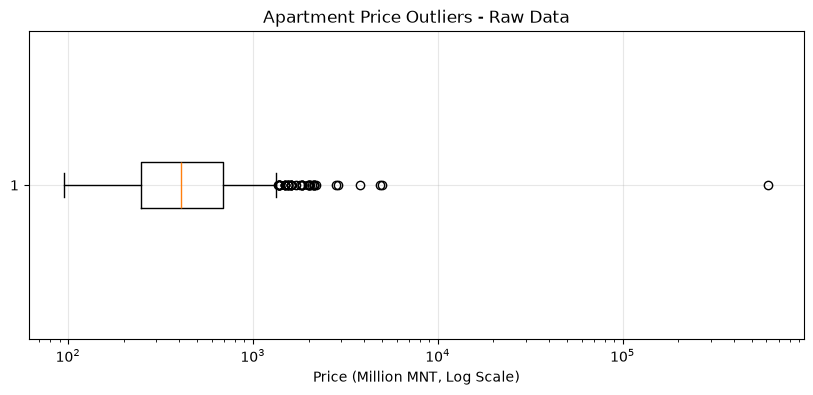

In [146]:
# Use a box plot to identify possible price outliers in the matched dataset. The logarithmic axis helps show very large prices.
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_matched.loc[df_matched["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

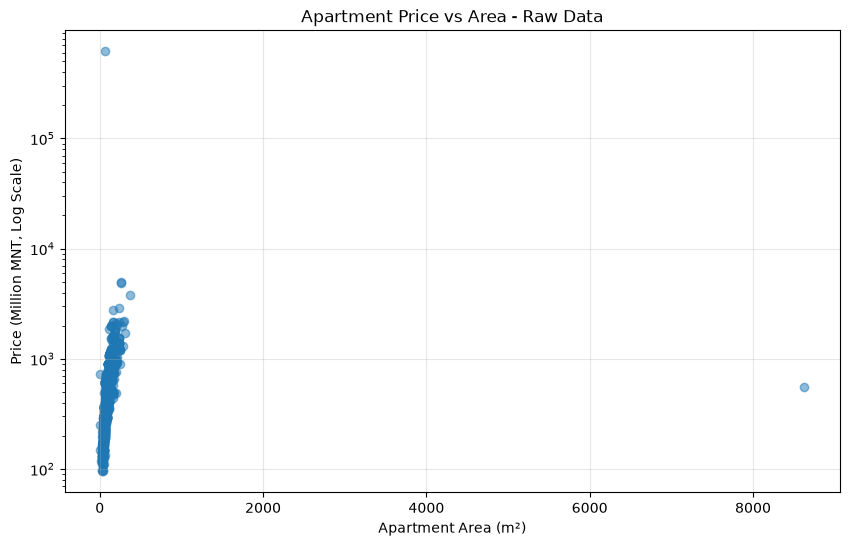

In [147]:
# Use a scatter plot to show the relationship between apartment area and asking price. Points far from the main group may need investigation.
# Select valid positive values for plotting.
plot_df = df_matched[(df_matched["area_m2"] > 0) & (df_matched["price_mnt"] > 0)].copy()

plt.figure(figsize=(10, 6))

plt.scatter(plot_df["area_m2"], plot_df["price_mnt"] / 1_000_000, alpha=0.5)

plt.yscale("log")
plt.title("Apartment Price vs Area - Raw Data")
plt.xlabel("Apartment Area (m²)")
plt.ylabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

**Purpose:** Calculate the interquartile range (IQR) of apartment prices. The code keeps rows inside the 1.5 × IQR limits in `df_no_outliers`. **Caution:** Valid expensive apartments can also fall outside these limits.

In [148]:
# Calculate the IQR for apartment prices.
Q1 = df_matched["price_mnt"].quantile(0.25)
Q3 = df_matched["price_mnt"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the lower and upper limits.
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Find price outliers.
outlier_mask = (df_matched["price_mnt"] < lower_limit) | (
    df_matched["price_mnt"] > upper_limit
)

price_outliers = df_matched.loc[outlier_mask].copy()

# Keep prices within the limits.
within_limits = df_matched["price_mnt"].between(lower_limit, upper_limit)

df_no_outliers = df_matched.loc[within_limits].copy()

# Show the results.
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Original rows:", len(df_matched))
print("Price outliers:", len(price_outliers))
print("Missing prices:", df_matched["price_mnt"].isna().sum())
print("Remaining rows:", len(df_no_outliers))

Lower limit: -409075000.0
Upper limit: 1343125000.0
Original rows: 962
Price outliers: 43
Missing prices: 0
Remaining rows: 919


C:\Users\dashk\AppData\Local\Temp\ipykernel_92488\190724417.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


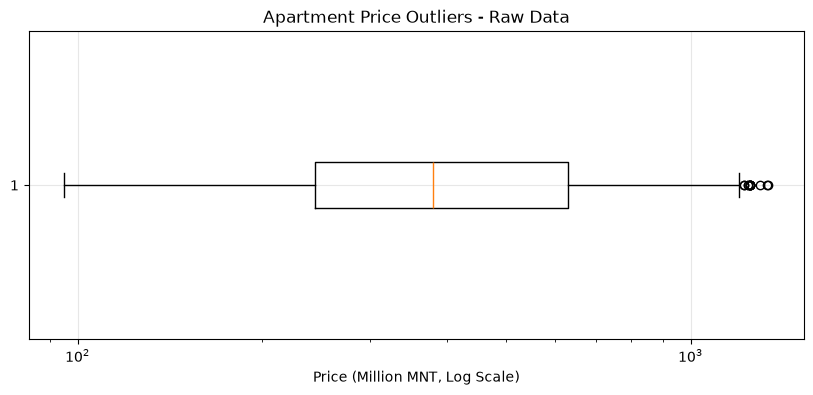

In [149]:
# Show the price box plot after the IQR price filter. The plot title still says `Raw Data`, although this code uses `df_no_outliers`.
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_no_outliers.loc[df_no_outliers["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

**Purpose:** Calculate IQR limits for apartment area and create `df_clean` using rows inside these limits. The area filter is applied after the price filter.

In [150]:
# Calculate the IQR for apartment areas.
Q1_area = df_no_outliers["area_m2"].quantile(0.25)
Q3_area = df_no_outliers["area_m2"].quantile(0.75)

IQR_area = Q3_area - Q1_area

# Calculate the lower and upper limits.
lower_area = Q1_area - 1.5 * IQR_area
upper_area = Q3_area + 1.5 * IQR_area

# Find area outliers.
area_outlier_mask = (df_no_outliers["area_m2"] < lower_area) | (
    df_no_outliers["area_m2"] > upper_area
)

area_outliers = df_no_outliers.loc[area_outlier_mask].copy()

# Keep areas within the limits.
within_area_limits = df_no_outliers["area_m2"].between(lower_area, upper_area)

df_clean = df_no_outliers.loc[within_area_limits].copy()

# Show the results.
print("Lower area limit:", lower_area)
print("Upper area limit:", upper_area)
print("Original rows:", len(df_no_outliers))
print("Area outliers:", len(area_outliers))
print("Missing areas:", df_no_outliers["area_m2"].isna().sum())
print("Remaining rows:", len(df_clean))


Lower area limit: -23.61250000000001
Upper area limit: 185.3675
Original rows: 919
Area outliers: 30
Missing areas: 0
Remaining rows: 889


**Purpose:** Display a price box plot using `df_clean`, after both IQR filters. The plot title still says `Raw Data` and should be interpreted with care.

C:\Users\dashk\AppData\Local\Temp\ipykernel_92488\2088605695.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


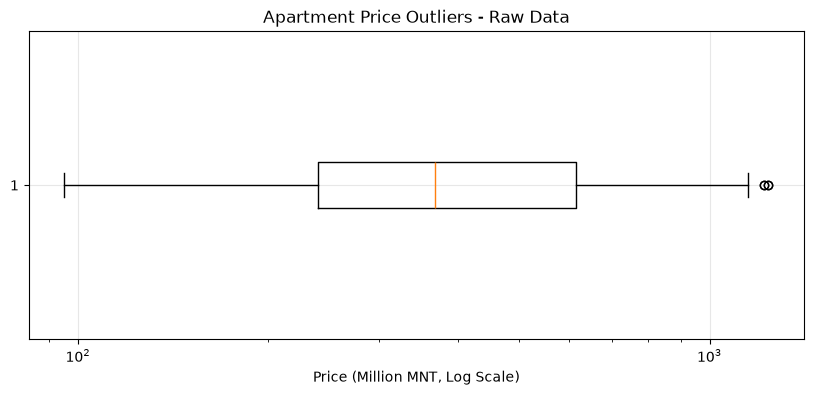

In [151]:
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_clean.loc[df_clean["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

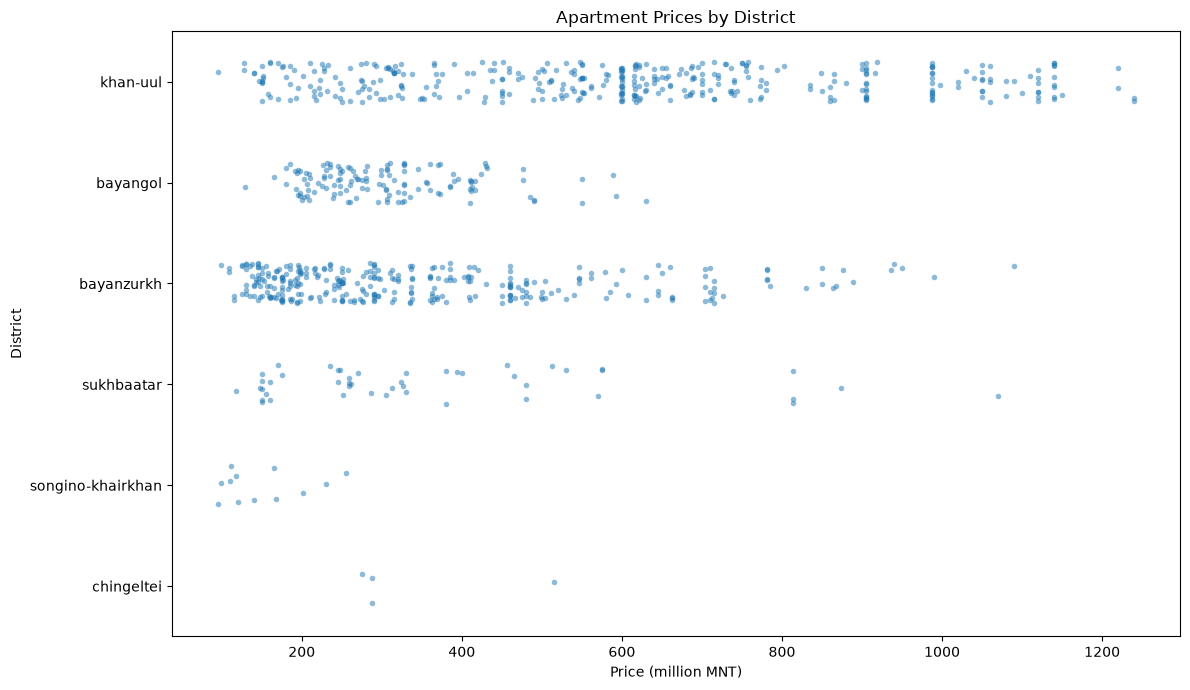

In [152]:
# Compare asking prices across districts using a strip plot. Each point represents one apartment listing.
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate DataFrame for plotting.
plot_data = df_clean.copy()
plot_data["price_million_mnt"] = plot_data["price_mnt"] / 1_000_000

# Create the plot.
fig, ax = plt.subplots(figsize=(12, 7))

sns.stripplot(
    data=plot_data,
    x="price_million_mnt",
    y="city_region",
    jitter=0.2,
    alpha=0.5,
    size=4,
    ax=ax,
)

ax.set_title("Apartment Prices by District")
ax.set_xlabel("Price (million MNT)")
ax.set_ylabel("District")

plt.tight_layout()
plt.show()

In [153]:
df_clean.head()

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,NaN,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,NaN,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,NaN,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,NaN,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,NaN,altai khotkhon


In [154]:
# output_path = project_dir / "data" / "df_clean.csv"
# df_clean.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("File saved to:", output_path.resolve())

In [155]:
# Basic statistics.
df_clean.describe()

,price_mnt,rooms,building_year,total_floors,area_m2,floor_number,window_count
count,8.890000e+02,889.0,889.000000,889.000000,889.000000,889.000000,889.000000
mean,4.483745e+08,2.788526,2017.922385,13.570304,80.780624,8.085489,3.376828
std,2.663243e+08,0.862274,5.204127,4.310559,34.608376,5.032720,1.321497
min,9.500000e+07,1.0,1990.000000,1.000000,1.000000,1.000000,1.000000
25%,2.400000e+08,2.0,2014.000000,11.000000,54.000000,4.000000,2.000000
50%,3.673400e+08,3.0,2018.000000,14.000000,72.210000,8.000000,3.000000
75%,6.156500e+08,3.0,2022.000000,16.000000,105.300000,11.000000,4.000000
max,1.240000e+09,5.0,2026.000000,25.000000,185.000000,25.000000,8.000000


**Purpose:** Remove apartments smaller than 15 m² and rows where the apartment floor is above the building's total floors.

In [156]:
# Find apartments with an area smaller than 15 m².
small_area = df_clean["area_m2"] < 15

# Find apartments with incorrect floor information.
wrong_floor = df_clean["floor_number"] > df_clean["total_floors"]

# Count records before cleaning.
before = len(df_clean)

# Remove invalid records and update df_clean.
df_clean = df_clean[~(small_area | wrong_floor)].copy()

# Check the results.
print("Removed records:", before - len(df_clean))
print("Remaining records:", len(df_clean))

# Display the updated dataset.
display(df_clean)

Removed records: 13
Remaining records: 876


,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,NaN,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,NaN,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,NaN,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,NaN,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,NaN,altai khotkhon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3737,364950000,3,khan-uul,parquet,1 balcony,2016,available,insulated glazing,5,metal,97.00,3,bank loan,4,completed,not available,2026-10-26,dol khotkhon
3738,147700000,2,bayanzurkh,parquet,no balcony,2013,not available,insulated glazing,5,security door,38.00,1,bank loan,2,completed,not available,2026-10-26,erdem khotkhon
3749,138000000,2,bayanzurkh,parquet,1 balcony,2011,not available,insulated glazing,5,security door,39.00,1,cash payment,2,completed,not available,2026-10-26,baianzurkh khotkhon
3763,275000000,3,bayanzurkh,parquet,2 balconies,2021,not available,insulated glazing,12,security door,77.00,11,bank loan,3,completed,available,2026-10-25,"nart khoroolol 1, 2"


In [157]:
# Remove the published_at column.
df_clean = df_clean.drop(columns=["published_at"])
# Check the remaining columns.
print(df_clean.columns.tolist())

['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony', 'building_year', 'garage', 'window_type', 'total_floors', 'door_type', 'area_m2', 'floor_number', 'payment_terms', 'window_count', 'construction_status', 'elevator', 'complex_name_clean']


In [158]:
df_clean.head()

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,altai khotkhon


#### 7. Exploratory Data Analysis (EDA)

**Figure 1 — Price distribution:** Show how many apartments fall into different price ranges. A vertical line marks the median asking price.

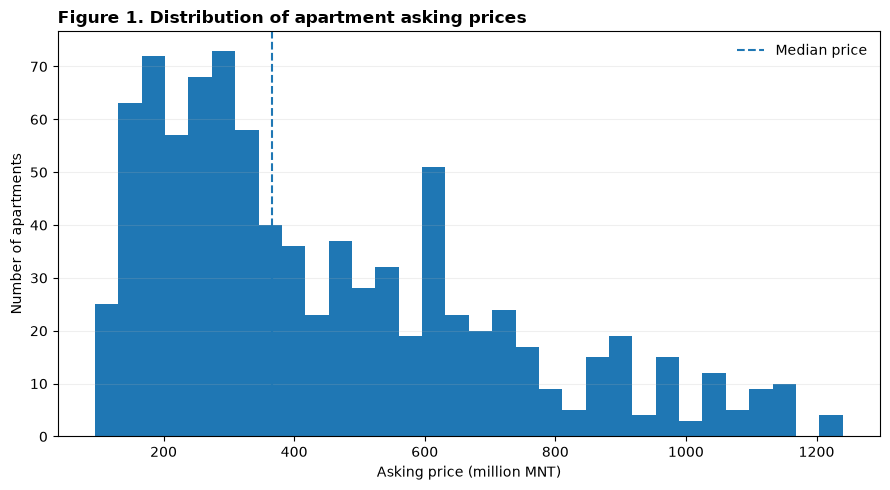

In [159]:
# Convert MNT into millions to make the axis easier to read.
prices = df_clean["price_mnt"] / 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(prices, bins=32)
ax.axvline(prices.median(), linestyle="--", label="Median price")
ax.set_title(
    "Figure 1. Distribution of apartment asking prices", loc="left", fontweight="bold"
)
ax.set_xlabel("Asking price (million MNT)")
ax.set_ylabel("Number of apartments")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("CA1_EDA_01_Price_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 2 — Floor area distribution:** Show the distribution of apartment sizes and mark the median floor area.

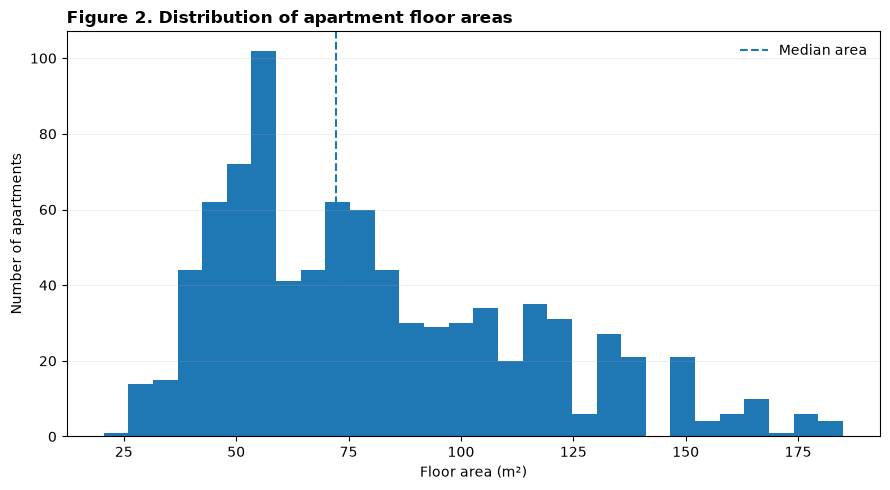

In [160]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df_clean["area_m2"], bins=30)
ax.axvline(df_clean["area_m2"].median(), linestyle="--", label="Median area")
ax.set_title(
    "Figure 2. Distribution of apartment floor areas", loc="left", fontweight="bold"
)
ax.set_xlabel("Floor area (m²)")
ax.set_ylabel("Number of apartments")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("CA1_EDA_02_Area_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 3 — Area vs price:** Display the relationship between size and asking price. **Note:** The code checks for areas below 15 m², but the earlier cleaning step already removed those rows.

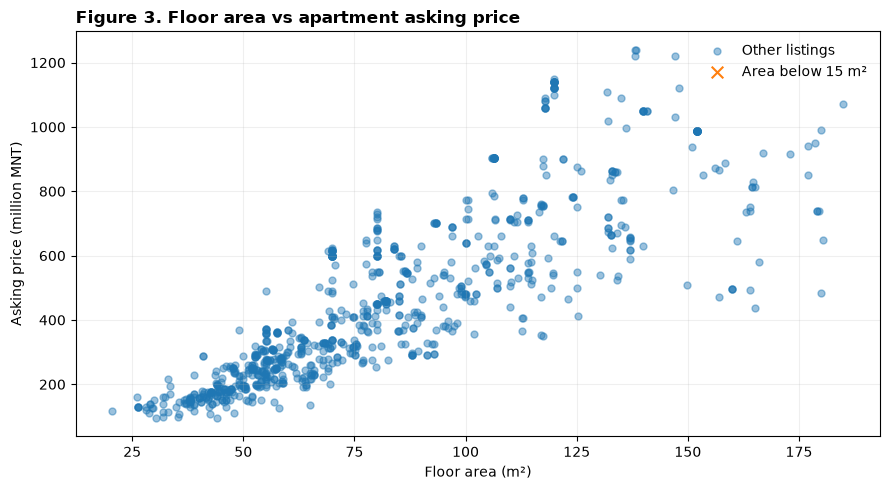

In [161]:
# Highlight extremely small areas so we do not forget to check them.
small = df_clean["area_m2"] < 15

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    df_clean.loc[~small, "area_m2"],
    df_clean.loc[~small, "price_mnt"] / 1_000_000,
    alpha=0.45,
    s=25,
    label="Other listings",
)
ax.scatter(
    df_clean.loc[small, "area_m2"],
    df_clean.loc[small, "price_mnt"] / 1_000_000,
    marker="x",
    s=70,
    label="Area below 15 m²",
)
ax.set_title(
    "Figure 3. Floor area vs apartment asking price", loc="left", fontweight="bold"
)
ax.set_xlabel("Floor area (m²)")
ax.set_ylabel("Asking price (million MNT)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_03_Area_vs_Price.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 4 — District comparison:** Compare median apartment asking prices across districts and print the number of listings in each district.

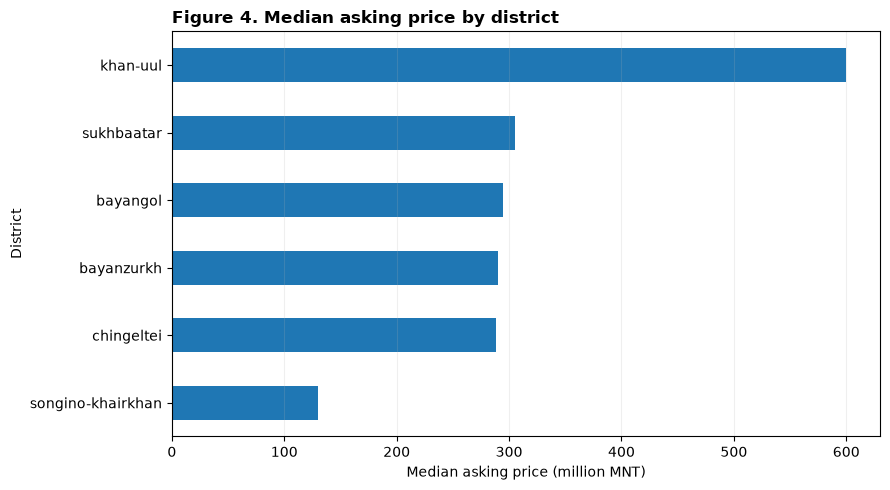

Listings by district:
city_region
khan-uul             368
bayanzurkh           314
bayangol             131
sukhbaatar            47
songino-khairkhan     12
chingeltei             4
Name: count, dtype: int64


In [162]:
district_price = (
    df_clean.groupby("city_region")["price_mnt"].median().sort_values() / 1_000_000
)

fig, ax = plt.subplots(figsize=(9, 5))
district_price.plot(kind="barh", ax=ax)
ax.set_title("Figure 4. Median asking price by district", loc="left", fontweight="bold")
ax.set_xlabel("Median asking price (million MNT)")
ax.set_ylabel("District")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_04_Median_Price_by_District.png", dpi=300, bbox_inches="tight")
plt.show()

print("Listings by district:")
print(df_clean["city_region"].value_counts())

**Figure 5 — Room comparison:** Compare median asking prices for different numbers of rooms.

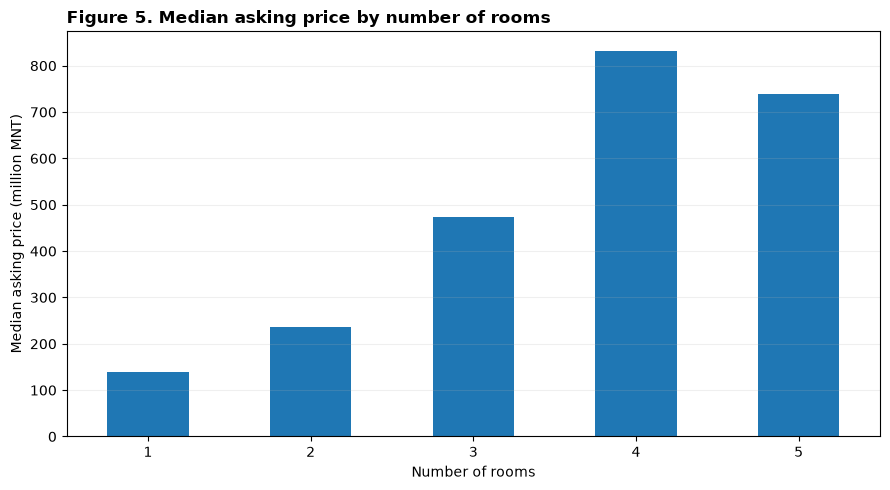

In [163]:
# Convert values such as "3 rooms" into the number 3.
# df_clean["room_number"] = df_clean["rooms"].str.extract(r"(\d+)").astype(int)
room_price = df_clean.groupby("rooms")["price_mnt"].median() / 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))
room_price.plot(kind="bar", ax=ax)
ax.set_title(
    "Figure 5. Median asking price by number of rooms", loc="left", fontweight="bold"
)
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Median asking price (million MNT)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_05_Median_Price_by_Rooms.png", dpi=300, bbox_inches="tight")
plt.show()

#### 8. Numerical Correlation Analysis

In [164]:
# Display the data types of the columns before calculating numerical correlations.
df_clean.dtypes

price_mnt                int64
rooms                    Int64
city_region                str
floor_material             str
balcony                    str
building_year            int64
garage                     str
window_type                str
total_floors             int64
door_type                  str
area_m2                float64
floor_number             int64
payment_terms              str
window_count             int64
construction_status        str
elevator                   str
complex_name_clean         str
dtype: object

**Purpose:** Calculate Pearson correlations between numeric property features and asking price, then draw a heatmap. Correlation shows linear association but does not prove that a feature causes a price change.

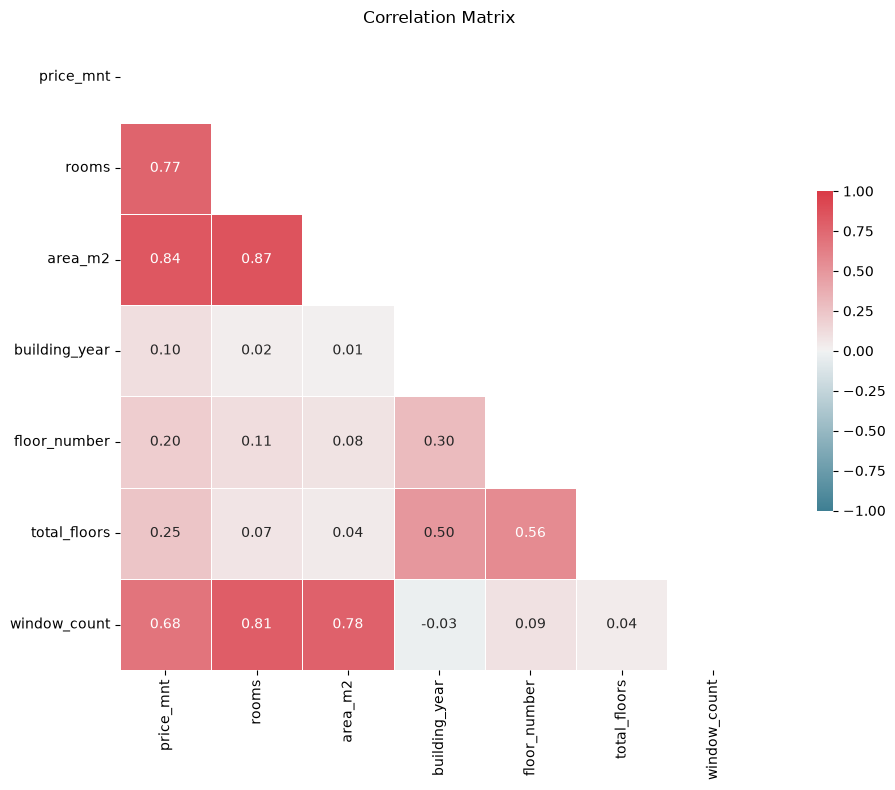

In [165]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select the columns for correlation analysis.
selected_columns = [
    "price_mnt",
    "rooms",
    "area_m2",
    "building_year",
    "floor_number",
    "total_floors",
    "window_count",
]

# Calculate the correlation matrix.
corr = df_clean[selected_columns].corr()

# Hide the upper triangle.
mask = np.triu(np.ones_like(corr, dtype=bool))

# Create the figure and colour palette.
fig, ax = plt.subplots(figsize=(12, 8))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

# Draw the heatmap.
sns.heatmap(
    corr,
    mask=mask,
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.5},
    ax=ax,
)

ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

#### 9. Random Forest Model Training and Evaluation

**Purpose:** Define `train()`, a function that trains a **Random Forest Regressor**, predicts apartment prices, calculates MAE, RMSE, and R², and creates residual and feature-importance plots. It measures performance on the provided test set.

In [166]:
# ==========================================================
# Random Forest Regressor: Model Training and Evaluation
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def train(X_train, Y_train, X_test, Y_test):

    # ==========================================================
    # 1. Model Training
    # ==========================================================

    # Create the model.
    model = RandomForestRegressor(random_state=42)
    # Train the model.
    model.fit(X_train, Y_train)

    # ==========================================================
    # 2. Prediction
    # ==========================================================

    # Predict apartment prices.
    predictions = model.predict(X_test)
    # Calculate residuals.
    residual = np.asarray(Y_test) - predictions

    # ==========================================================
    # 3. Model Evaluation: MAE, RMSE and R²
    # ==========================================================

    mae = mean_absolute_error(Y_test, predictions)
    rmse = np.sqrt(mean_squared_error(Y_test, predictions))
    r2 = r2_score(Y_test, predictions)

    print("=" * 45)
    print("RANDOM FOREST MODEL EVALUATION")
    print("=" * 45)
    print("Selected Model: Random Forest")
    print(f"Test MAE:  {mae / 1e6:.2f} million MNT")
    print(f"Test RMSE: {rmse / 1e6:.2f} million MNT")
    print(f"Test R²:   {r2:.4f}")
    print("=" * 45)

    # ==========================================================
    # 4. Actual vs Predicted Apartment Prices
    # ==========================================================

    actual = np.asarray(Y_test)

    # Display the last 100 test records.
    plt.figure(figsize=(10, 5))
    plt.plot(actual[-100:] / 1e6, label="Actual Price")
    plt.plot(predictions[-100:] / 1e6, label="Predicted Price")
    plt.title("Actual vs Predicted Apartment Prices")
    plt.xlabel("Test Sample Number")
    plt.ylabel("Apartment Price (Million MNT)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # 5. Residual Distribution
    # ==========================================================

    plt.figure(figsize=(10, 5))
    sns.histplot(x=residual / 1e6, bins=30, kde=True, color="teal")
    plt.title("Residual Distribution")
    plt.xlabel("Residual (Million MNT)")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # 6. Residuals vs Predicted Prices
    # ==========================================================

    plt.figure(figsize=(10, 5))
    plt.scatter(predictions / 1e6, residual / 1e6, color="teal", alpha=0.5)
    plt.axhline(y=0, color="red", linestyle="--")
    plt.title("Residuals vs Predicted Prices")
    plt.xlabel("Predicted Price (Million MNT)")
    plt.ylabel("Residual (Million MNT)")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # 7. Feature Importance Analysis
    # ==========================================================

    # Get feature importance values.
    importances = pd.Series(model.feature_importances_, index=X_train.columns)
    # Find apartment-name dummy columns.
    apartment_columns = importances.index.str.startswith("complex_name_clean_")
    # Combine apartment-name importances.
    summary = importances.loc[~apartment_columns].copy()
    summary["complex_name_clean"] = importances.loc[apartment_columns].sum()
    # Sort features from highest to lowest importance.
    summary = summary.sort_values(ascending=False)

    print("\n" + "=" * 45)
    print("RANDOM FOREST FEATURE IMPORTANCE")
    print("=" * 45)

    for feature, importance in summary.items():
        print(f"{feature:<25} {importance * 100:.2f}%")
    print("=" * 45)

    # ==========================================================
    # 8. Feature Importance Visualisation
    # ==========================================================

    summary.sort_values().plot(kind="barh", figsize=(8, 4), color="teal", width=0.3)
    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # 9. Return the Trained Model
    # ==========================================================

    return model

In [167]:
df_clean.columns

Index(['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'complex_name_clean'],
      dtype='str')

In [168]:
df_clean.dtypes

price_mnt                int64
rooms                    Int64
city_region                str
floor_material             str
balcony                    str
building_year            int64
garage                     str
window_type                str
total_floors             int64
door_type                  str
area_m2                float64
floor_number             int64
payment_terms              str
window_count             int64
construction_status        str
elevator                   str
complex_name_clean         str
dtype: object

**Purpose:** Select `rooms`, `building_year`, `area_m2`, and `complex_name_clean` as inputs. Convert the apartment name into dummy columns, make an 80/20 train/test split, then train the Random Forest model. **Note:** The variable `gbr` holds a Random Forest model in this code, despite its name.

RANDOM FOREST MODEL EVALUATION
Selected Model: Random Forest
Test MAE:  40.27 million MNT
Test RMSE: 65.78 million MNT
Test R²:   0.9333


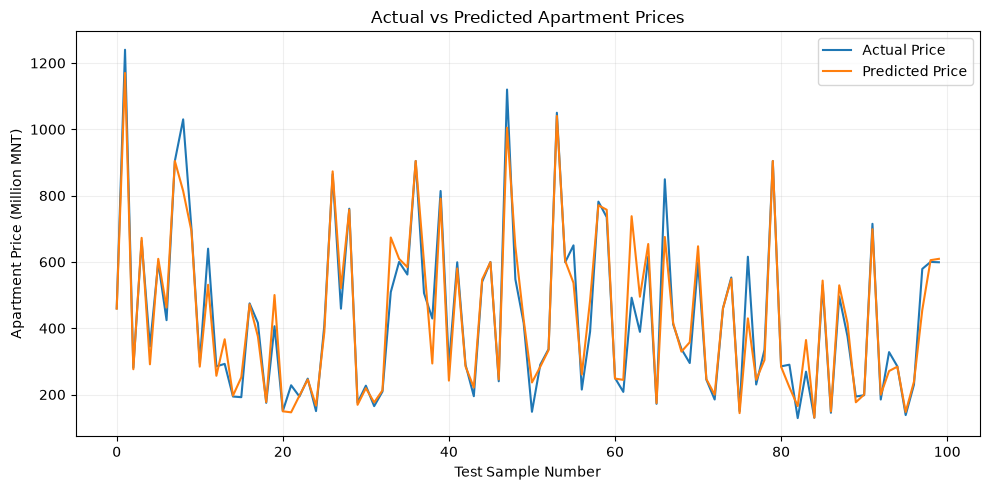

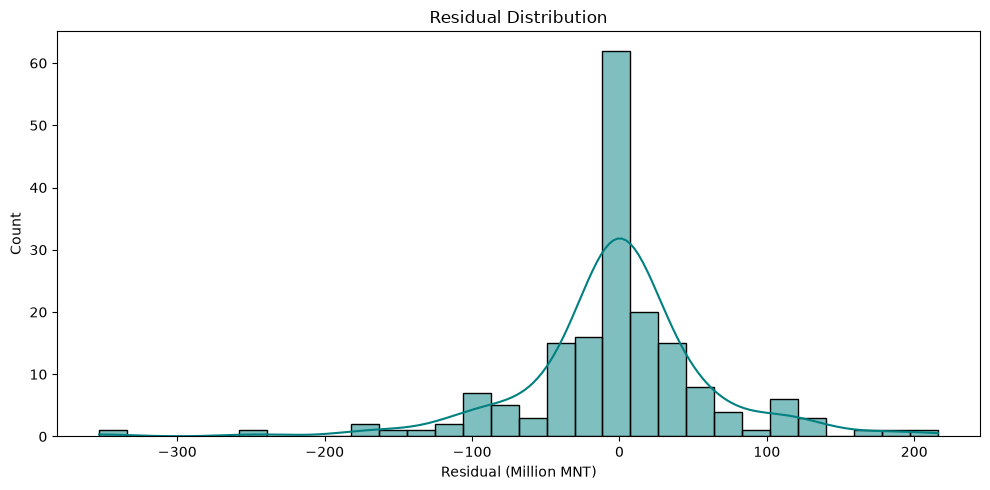

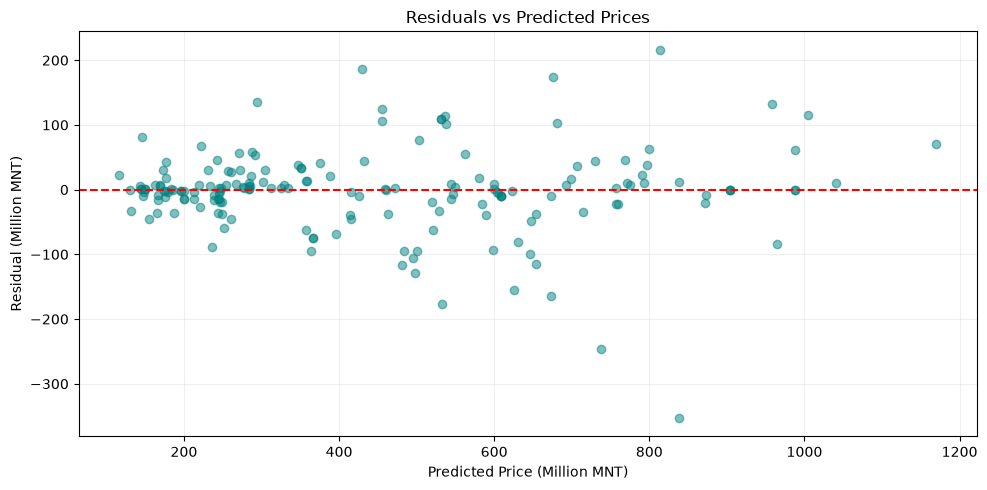


RANDOM FOREST FEATURE IMPORTANCE
area_m2                   80.40%
complex_name_clean        15.37%
building_year             3.04%
rooms                     1.18%


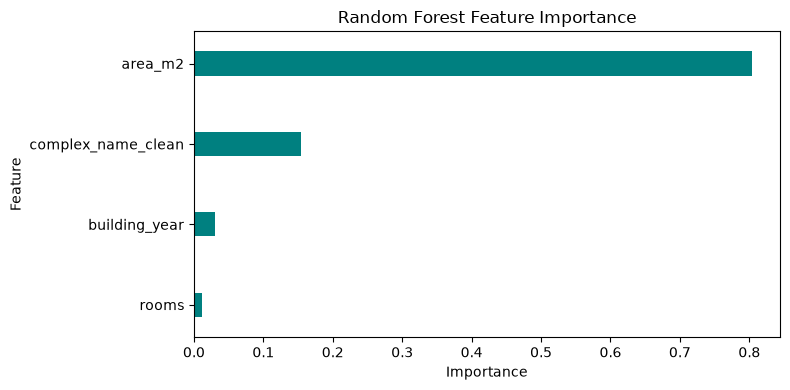

Training data: (700, 149)
Testing data: (176, 149)


In [169]:
from sklearn.model_selection import train_test_split

Y = df_clean["price_mnt"]
X = df_clean[["rooms", "building_year", "area_m2", "complex_name_clean"]].copy()
# Convert text categories into numeric dummy columns.
X = pd.get_dummies(X, dtype=int)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42
)
gbr = train(X_train, Y_train, X_test, Y_test)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

#### 10. Predicting the Price of a New Apartment

**Purpose:** Define a helper function to prepare one new apartment with the same dummy columns as the training data. An unknown complex name raises an error.

In [170]:
def prepare_apartment(details, training_columns):

    # Create one row with the same columns as the training data.
    encoded = pd.DataFrame(0, index=[0], columns=training_columns)

    # Fill the numerical features.
    encoded["rooms"] = details["rooms"]
    encoded["building_year"] = details["building_year"]
    encoded["area_m2"] = details["area_m2"]

    # Find the apartment's dummy column.
    complex_column = "complex_name_clean_" + details["complex_name_clean"]

    if complex_column not in training_columns:
        raise ValueError("Apartment complex name was not found in training columns.")

    # Mark the selected apartment complex.
    encoded.loc[0, complex_column] = 1

    return encoded

**Purpose:** Create an example apartment, prepare its features, and predict the asking price in MNT using the trained model. This is a demonstration, not a confirmed market valuation.

In [171]:
apartment_details = {
    "rooms": 2,
    "building_year": 2019,
    "area_m2": 56,
    "complex_name_clean": "king tauer",
}

new_apartment = prepare_apartment(apartment_details, X_train.columns)
predicted_price = gbr.predict(new_apartment)[0]
print("Selected Model:", "Random Forest Regressor")
print(f"Predicted price: {predicted_price:,.0f} MNT")

Selected Model: Random Forest Regressor
Predicted price: 365,686,900 MNT


#### 11. Training-Size Comparison with Cross-Validation

**Purpose:** Compare two regression models using **5%, 15%, and 25% of the dataset for training**. Five-fold cross-validation is applied.

**Models:** Linear Regression and Random Forest. 

**Metrics:** Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R². For price prediction, these regression metrics are more suitable than classification accuracy.

**Select features and prepare the models:**
Use the same four features as the Random Forest model in Section 9. We use a preprocessing **Pipeline** so missing-value imputation and categorical encoding are fitted separately within each cross-validation fold.

In [172]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Use the same four features as the current project model.
numeric_features_cv = ["rooms", "building_year", "area_m2"]
categorical_features_cv = ["complex_name_clean"]

X_experiment = df_clean[numeric_features_cv + categorical_features_cv].copy()
y_experiment = pd.to_numeric(df_clean["price_mnt"], errors="coerce")

# Convert numbers safely without learning any values from the full dataset.
for col in numeric_features_cv:
    X_experiment[col] = pd.to_numeric(X_experiment[col], errors="coerce")

# Convert apartment names to ordinary text for the encoder.
X_experiment["complex_name_clean"] = X_experiment["complex_name_clean"].astype("object")

# Keep only records with a valid target price.
valid_target = y_experiment.notna() & (y_experiment > 0)
X_experiment = X_experiment.loc[valid_target].copy()
y_experiment = y_experiment.loc[valid_target].copy()

# Learn numeric imputation and categorical encoding on each training fold.
preprocessor_cv = ColumnTransformer(
    [
        ("numeric", SimpleImputer(strategy="median"), numeric_features_cv),
        (
            "categorical",
            Pipeline(
                [
                    (
                        "imputer",
                        SimpleImputer(strategy="constant", fill_value="Unknown"),
                    ),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features_cv,
        ),
    ]
)

models_cv = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
}

kf_cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Records for the experiments:", len(X_experiment))


Records for the experiments: 876


#### Compare training sizes using 5-fold cross-validation
For each training size, create a new split and run both models using **only its training subset**. Keep the rest separate. Each model's preprocessing is fitted again during cross-validation.

In [173]:
training_sizes = [0.05, 0.15, 0.25]
split_results = []

for train_size in training_sizes:
    # Use the specified fraction for training, and hold back the rest.
    X_small_train, X_small_test, y_small_train, y_small_test = train_test_split(
        X_experiment, y_experiment, train_size=train_size, random_state=42
    )

    for model_name, estimator in models_cv.items():
        pipeline = Pipeline(
            [("preprocessing", clone(preprocessor_cv)), ("model", clone(estimator))]
        )
        # The cross-validation uses the training records only.
        scores = cross_validate(
            pipeline,
            X_small_train,
            y_small_train,
            cv=kf_cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error",
                "r2": "r2",
            },
            return_train_score=True,
        )

        split_results.append(
            {
                "Model": model_name,
                "Training Size (%)": int(train_size * 100),
                "Training Rows": len(X_small_train),
                "Held-out Rows": len(X_small_test),
                "CV MAE (million MNT)": -scores["test_mae"].mean() / 1e6,
                "CV RMSE (million MNT)": -scores["test_rmse"].mean() / 1e6,
                "CV R²": scores["test_r2"].mean(),
                "Training R²": scores["train_r2"].mean(),
            }
        )

split_results_df = pd.DataFrame(split_results)
display(split_results_df.round(3))


,Model,Training Size (%),Training Rows,Held-out Rows,CV MAE (million MNT),CV RMSE (million MNT),CV R²,Training R²
0,Linear Regression,5,43,833,87.429,125.973,0.387,0.994
1,Random Forest,5,43,833,95.080,131.498,0.316,0.945
2,Linear Regression,15,131,745,62.148,82.766,0.881,0.968
3,Random Forest,15,131,745,71.799,105.573,0.804,0.973
4,Linear Regression,25,219,657,56.342,78.329,0.898,0.964
5,Random Forest,25,219,657,58.345,89.824,0.872,0.982


#### Visualise cross-validation results
The chart compares validation MAE in **million MNT**. Lower MAE is better.

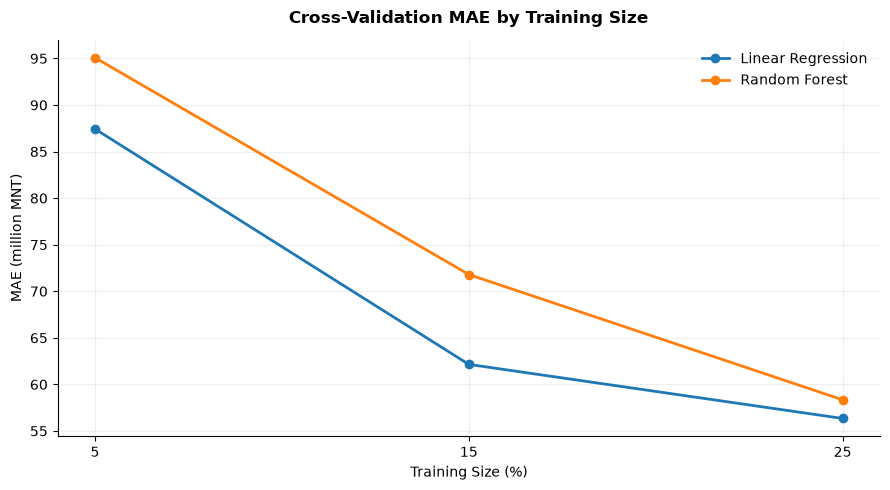

In [174]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, group in split_results_df.groupby("Model"):
    group = group.sort_values("Training Size (%)")
    ax.plot(
        group["Training Size (%)"],
        group["CV MAE (million MNT)"],
        marker="o",
        linewidth=2,
        label=model_name,
    )

ax.set_title("Cross-Validation MAE by Training Size", fontweight="bold", pad=12)
ax.set_xlabel("Training Size (%)")
ax.set_ylabel("MAE (million MNT)")
ax.set_xticks([5, 15, 25])
ax.grid(alpha=0.2)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


**Interpretation of Cross-Validation Results:**
The results show that the training size has a clear effect on model performance. Both Linear Regression and Random Forest performed poorly with only `5%` of the dataset used for training. Their cross-validation `R² scores` were 0.387 and 0.316, respectively. This suggests that 43 training records were not enough to produce reliable predictions.
When the training size increased to `15%`, both models improved significantly. Their performance improved further at `25%`.
`Linear Regression` achieved the best overall cross-validation results at the 25% training size, with an `MAE` of 56.34 million MNT, an `RMSE` of 78.33 million MNT, and an `R² score` of 0.898. Although `Random Forest` achieved a higher training `R² score` of 0.982 at 25%, its `cross-validation R²` was lower at 0.872. This gap suggests some overfitting.
Overall, `Linear Regression` showed better generalisation across the three training sizes. However, further hyperparameter tuning and final testing are needed before selecting the final model.